# Chapitre 18 - Problèmes en grande dimension ($p \gg N$)
## Cours 2 : régularisation quadratique, astuce du noyau, pénalités L1, classification sans variables

Plan (sections 18.3 à 18.5 du livre) :

1. classifieurs linéaires à **pénalité quadratique** (RDA, logistique ridge, SVM) ;
2. l'**astuce de calcul** : quand $p > N$, tout se ramène à un problème en dimension
   $N$ grâce à la SVD (coût $O(N^2p)$ au lieu de $O(p^3)$) ;
3. pénalités **L1** : lasso, elastic net, *fused lasso* ;
4. classification quand on ne dispose que de **produits scalaires** ou de
   **distances** (noyaux de chaînes, centroïdes, ACP à noyau).

In [1]:
import time
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

from esl import datasets
from esl import ch18_grande_dimension as g

## 1. Classifieurs linéaires à pénalité quadratique

### 1.1 Analyse discriminante régularisée (RDA)

La LDA utilise l'inverse de la matrice de covariance intra-classe $\hat\Sigma$
($p\times p$). Quand $p \gg N$, $\hat\Sigma$ est de rang au plus $N - K$ : elle est
singulière. La RDA la remplace par un mélange avec sa diagonale (éq. (18.9) du livre) :
$$\hat\Sigma(\gamma) = \gamma\,\hat\Sigma + (1-\gamma)\operatorname{diag}(\hat\Sigma), \qquad \gamma\in[0,1].$$
Pour $\gamma < 1$, $\hat\Sigma(\gamma)$ est définie positive (somme d'une matrice
positive et d'une matrice diagonale à termes $> 0$), donc inversible.
$\gamma = 0$ redonne la **LDA diagonale** du cours 1 ; $\gamma \to 1$ la LDA complète.

> **Intuition.** C'est l'analogue de la ridge : on « tire » la covariance estimée
> vers une matrice diagonale, ce qui stabilise son inversion. L'exercice 18.6 montre
> que le calcul se fait, lui aussi, en dimension $N$.

### 1.2 Régression logistique multinomiale ridge

Avec $K$ classes, on utilise la forme **symétrique** du modèle logistique
(éq. (18.10)) :
$$\Pr(G = k\mid X = x) = \frac{\exp(\beta_{k0} + x^T\beta_k)}{\sum_{\ell=1}^K \exp(\beta_{\ell 0} + x^T\beta_\ell)},$$
avec un vecteur $\beta_k\in\mathbb R^p$ **par classe**. Sans pénalité ce modèle est
sur-paramétré (ajouter le même vecteur à tous les $\beta_k$ ne change pas les
probabilités). On maximise la log-vraisemblance pénalisée (éq. (18.11)) :
$$\max_{\{\beta_{k0},\beta_k\}}\ \sum_{i=1}^N \log\Pr(g_i\mid x_i) - \frac\lambda2\sum_{k=1}^K\|\beta_k\|_2^2 .$$
La pénalité lève l'indétermination et impose $\sum_k\hat\beta_{kj} = 0$ pour chaque
$j$ (exercice 18.3). Le problème est **concave** (log-vraisemblance concave moins
une fonction convexe) : un algorithme de type Newton ou quasi-Newton le résout.

### 1.3 Le classifieur à vecteurs supports (SVM)

Quand $p > N$, deux classes sont en général **linéairement séparables** (sauf si deux
observations identiques ont des classes différentes) : $N$ points en dimension
$p \ge N$ peuvent recevoir n'importe quelles valeurs $x_i^T\beta$. Le SVM sans
régularisation trouve alors l'hyperplan séparateur de **marge maximale**
(section 12.2). Le livre note qu'en pratique, quand $p\gg N$, ce SVM « dur »
fonctionne souvent aussi bien que ses versions régularisées.

## 2. L'astuce de calcul quand $p > N$ (section 18.3.5)

**Idée géométrique** : $N$ points de $\mathbb R^p$ vivent dans un sous-espace de
dimension au plus $N$ (deux points de $\mathbb R^3$ sont toujours sur une droite).
On peut donc tourner les axes pour que seules $N$ coordonnées soient non nulles.

On écrit la SVD réduite (éq. (18.12)-(18.13)) :
$$\mathbf X = \mathbf U\mathbf D\mathbf V^T = \mathbf R\mathbf V^T,\qquad \mathbf R = \mathbf U\mathbf D\ (N\times N),$$
où $\mathbf V$ ($p\times N$) a des colonnes orthonormées ($\mathbf V^T\mathbf V = I_N$)
et $\mathbf U$ est $N\times N$ orthogonale. La ligne $i$ de $\mathbf R$, notée
$r_i^T$, donne les **coordonnées** de $x_i$ dans la base des colonnes de $\mathbf V$ :
$x_i = \mathbf V r_i$.

**Ridge en dimension $N$.** La solution ridge (18.14)
$\hat\beta = (\mathbf X^T\mathbf X+\lambda I)^{-1}\mathbf X^Ty$ s'écrit aussi
(éq. (18.15), démontrée à l'exercice 18.4) :
$$\hat\beta = \mathbf V(\mathbf R^T\mathbf R + \lambda I_N)^{-1}\mathbf R^Ty .$$
Autrement dit $\hat\beta = \mathbf V\hat\theta$, où $\hat\theta$ est la ridge calculée
sur les $N$ observations $(r_i, y_i)$ à $N$ variables.

**Coût.** La SVD d'une matrice $N\times p$ coûte $O(N^2p)$ ; il reste ensuite à
résoudre un système $N\times N$. Le calcul direct résout un système $p\times p$ :
$O(p^3)$. Pour $p = 6830$ et $N = 57$, le rapport est de l'ordre de
$p^2/N^2 \approx 1{,}4\cdot 10^4$.

Vérifions numériquement l'égalité des deux formules.

In [2]:
rng = np.random.RandomState(0)
N, p = 50, 2000
Xs = rng.randn(N, p)
ys = Xs[:, :10].sum(1) + rng.randn(N)
b_direct = g.ridge_direct(Xs, ys, 5.0)
b_svd = g.ridge_svd(Xs, ys, 5.0)
print("écart max entre les deux formules :", np.max(np.abs(b_direct - b_svd)))

écart max entre les deux formules : 5.731526364627371e-15


Comparons les temps de calcul quand $p$ augmente ($N = 50$ fixé).

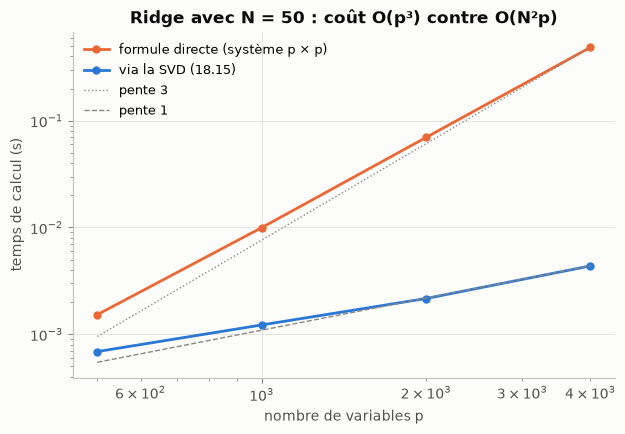

In [3]:
def best_time(f, n_rep=3):
    """Meilleur temps sur n_rep exécutions (moins sensible à la charge de la machine)."""
    best = np.inf
    for _ in range(n_rep):
        t0 = time.perf_counter()
        f()
        best = min(best, time.perf_counter() - t0)
    return best


p_list = [500, 1000, 2000, 4000]
t_dir, t_svd = [], []
for p in p_list:
    Xp = rng.randn(50, p)
    yp = rng.randn(50)
    t_dir.append(best_time(lambda: g.ridge_direct(Xp, yp, 1.0)))
    t_svd.append(best_time(lambda: g.ridge_svd(Xp, yp, 1.0)))
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(p_list, t_dir, "o-", color=ORANGE, label="formule directe (système p × p)")
ax.loglog(p_list, t_svd, "o-", color=BLUE, label="via la SVD (18.15)")
pp = np.array(p_list, dtype=float)
ax.loglog(pp, t_dir[-1] * (pp / pp[-1]) ** 3, ":", color=GRAY, lw=1, label="pente 3")
ax.loglog(pp, t_svd[-1] * (pp / pp[-1]), "--", color=GRAY, lw=1, label="pente 1")
ax.set_xlabel("nombre de variables p")
ax.set_ylabel("temps de calcul (s)")
ax.set_title("Ridge avec N = 50 : coût O(p³) contre O(N²p)")
ax.legend()
plt.show()

La formule directe est toujours bien plus lente, et l'écart se creuse quand $p$
augmente : en théorie, sur une échelle log-log, la pente vaut 3 pour le calcul direct
(coût cubique) et 1 pour la SVD (coût linéaire en $p$), voir les droites grises. Les
temps mesurés dépendent de la machine, de sa charge et de la bibliothèque d'algèbre
linéaire (parallélisme) : seule la tendance compte.

### Le théorème général (éq. (18.16)-(18.17))

Le résultat vaut pour **tout modèle linéaire à pénalité quadratique**. Soit une perte
$L$ quelconque (moins la log-vraisemblance logistique, par exemple) et les deux
problèmes
$$\begin{aligned}
(\hat\beta_0,\hat\beta) &= \arg\min_{\beta_0,\ \beta\in\mathbb R^p}\ \sum_{i=1}^N L(y_i, \beta_0 + x_i^T\beta) + \lambda\,\beta^T\beta ,\\
(\hat\theta_0,\hat\theta) &= \arg\min_{\theta_0,\ \theta\in\mathbb R^N}\ \sum_{i=1}^N L(y_i, \theta_0 + r_i^T\theta) + \lambda\,\theta^T\theta .
\end{aligned}$$
Alors $\hat\beta_0 = \hat\theta_0$ et $\hat\beta = \mathbf V\hat\theta$.

**Idée de la preuve** (détaillée à l'exercice 18.5). On décompose
$\beta = \mathbf V\theta + \beta_\perp$ avec $\mathbf V^T\beta_\perp = 0$. Alors
$x_i^T\beta = r_i^T\mathbf V^T\mathbf V\theta + r_i^T\mathbf V^T\beta_\perp = r_i^T\theta$ :
la perte ne dépend pas de $\beta_\perp$. Par Pythagore,
$\|\beta\|^2 = \|\theta\|^2 + \|\beta_\perp\|^2$ : la pénalité est minimale pour
$\beta_\perp = 0$. Ce n'est vrai que parce que la pénalité est **invariante par
rotation** - ce qui n'est pas le cas de la pénalité L1 du lasso.

**Vérification sur une logistique ridge** ($N = 40$, $p = 1000$). On ajuste le
modèle (par Newton-Raphson) une fois avec les $x_i \in\mathbb R^{1000}$, une fois
avec les $r_i\in\mathbb R^{40}$.

In [4]:
rng = np.random.RandomState(1)
Xl = rng.randn(40, 1000)
yl = (Xl[:, :5].sum(1) + rng.randn(40) > 0).astype(float)
t0 = time.perf_counter()
b0_full, b_full = g.ridge_logistic(Xl, yl, lam=2.0)
t_full = time.perf_counter() - t0
t0 = time.perf_counter()
R, V = g.svd_reduce(Xl)
th0, th = g.ridge_logistic(R, yl, lam=2.0)
t_red = time.perf_counter() - t0
print(f"|beta0 - theta0|        = {abs(b0_full - th0):.2e}")
print(f"max |beta - V theta|    = {np.max(np.abs(b_full - V @ th)):.2e}")
print(f"temps : p = 1000 -> {t_full:.2f} s ; réduit (N = 40) -> {t_red:.3f} s")

|beta0 - theta0|        = 7.77e-16
max |beta - V theta|    = 1.27e-16
temps : p = 1000 -> 0.08 s ; réduit (N = 40) -> 0.001 s


> **Remarque (astuce du noyau).** Si l'on ne connaît que la matrice de Gram
> $\mathbf K = \mathbf X\mathbf X^T$ ($N\times N$), on a
> $\mathbf K = \mathbf U\mathbf D^2\mathbf U^T$ : la décomposition spectrale de
> $\mathbf K$ fournit $\mathbf R = \mathbf U\mathbf D$, donc **toute l'information
> nécessaire**. C'est le principe de l'« astuce du noyau » des SVM (section 12.3.7) ;
> voir l'exercice 18.13.

### Application : logistique multinomiale ridge sur NCI

Reprenons les 8 types de cancer de NCI et le même découpage apprentissage / test que
dans le cours 1. Après centrage, on réduit les $39\times 6830$ données d'apprentissage
à une matrice $\mathbf R$ de taille $39 \times 39$ ; les points test sont projetés par
$r_0 = \mathbf V^T(x_0 - \bar x)$.

In [5]:
X_all, lab_all = datasets.load_nci()
types, counts = np.unique(lab_all, return_counts=True)
keep = np.isin(lab_all, types[counts >= 5])
X, lab = X_all[keep], lab_all[keep]
split = g.stratified_folds(lab, 3, np.random.RandomState(0))   # même découpage qu'au cours 1
te, tr = split == 0, split != 0
Xtr, ytr, Xte, yte = X[tr], lab[tr], X[te], lab[te]

mu = Xtr.mean(0)
R, V = g.svd_reduce(Xtr - mu)
Rte = (Xte - mu) @ V
print("R :", R.shape, "  V :", V.shape)

R : (39, 39)   V : (6830, 39)


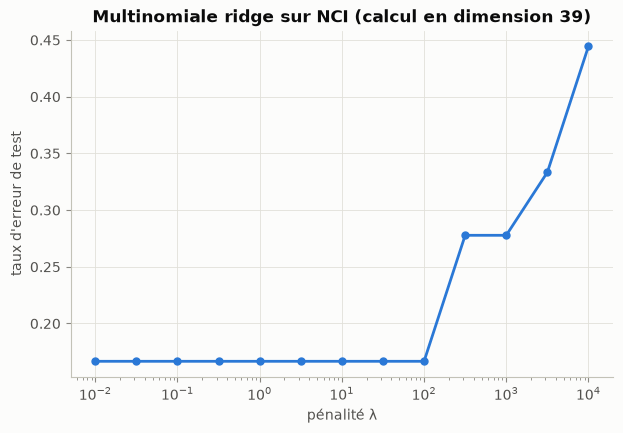

In [6]:
lam_grid = np.logspace(-2, 4, 13)
err_multi = []
for lam in lam_grid:
    cl, B0, B = g.ridge_multinomial(R, ytr, lam)
    err_multi.append(np.mean(cl[np.argmax(B0 + Rte @ B, axis=1)] != yte))
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.semilogx(lam_grid, err_multi, "o-", color=BLUE)
ax.set_xlabel("pénalité λ")
ax.set_ylabel("taux d'erreur de test")
ax.set_title("Multinomiale ridge sur NCI (calcul en dimension 39)")
plt.show()

Sur une large plage de $\lambda$ l'erreur de test est stable (3 erreurs sur 18) ; elle
ne se dégrade que pour une pénalité très forte. Comme le note le livre, quand
$p \gg N$ les données sont séparables et l'ajustement est peu sensible à $\lambda$ en
deçà d'un certain seuil.

**Comparaison de quelques méthodes** sur ce découpage (analogue, en plus modeste, du
tableau 18.1). Le SVM « un contre tous » est calculé avec scikit-learn (nous ne le
recodons pas ici ; il a été étudié au chapitre 12), le reste à la main.

In [7]:
from sklearn.svm import SVC


def nearest_centroid(Xa, ya, Xb):
    cls = np.unique(ya)
    C = np.array([Xa[ya == c].mean(0) for c in cls])
    return cls[np.argmin(((Xb[:, None, :] - C[None]) ** 2).sum(2), axis=1)]


def one_nn(Xa, ya, Xb):
    D = ((Xb[:, None, :] - Xa[None]) ** 2).sum(2)
    return ya[np.argmin(D, axis=1)]


cl, B0, B = g.ridge_multinomial(R, ytr, 1.0)
svm_scores = np.column_stack([
    SVC(kernel="linear", C=1e3).fit(Xtr, ytr == c).decision_function(Xte)
    for c in np.unique(ytr)])
results = {
    "LDA diagonale (Δ = 0)": g.NearestShrunkenCentroids(0.0).fit(Xtr, ytr).predict(Xte),
    "centroïdes réduits (Δ = 2)": g.NearestShrunkenCentroids(2.0).fit(Xtr, ytr).predict(Xte),
    "centroïde le plus proche": nearest_centroid(Xtr, ytr, Xte),
    "1 plus proche voisin": one_nn(Xtr, ytr, Xte),
    "multinomiale ridge (λ = 1)": cl[np.argmax(B0 + Rte @ B, axis=1)],
    "SVM linéaire un contre tous": np.unique(ytr)[np.argmax(svm_scores, axis=1)],
}
for name, pred in results.items():
    print(f"{name:30s} : {np.sum(pred != yte):2d} erreurs sur {len(yte)}")

LDA diagonale (Δ = 0)          :  4 erreurs sur 18
centroïdes réduits (Δ = 2)     :  4 erreurs sur 18
centroïde le plus proche       :  4 erreurs sur 18
1 plus proche voisin           :  3 erreurs sur 18
multinomiale ridge (λ = 1)     :  3 erreurs sur 18
SVM linéaire un contre tous    :  3 erreurs sur 18


Avec 18 échantillons test (écart-type d'une erreur estimée $\approx 2$ erreurs), ces
différences ne sont pas significatives : comme dans le tableau 18.1 du livre, les
méthodes « simples » et les méthodes à pénalité quadratique font jeu égal.

## 3. Pénalités L1 : sélection automatique de variables

Les pénalités quadratiques donnent des coefficients **tous non nuls** : aucune
sélection de variables. Le **lasso** (éq. (18.18)) remplace $\|\beta\|_2^2$ par
$\|\beta\|_1 = \sum_j|\beta_j|$ :
$$\min_\beta\ \frac12\sum_{i=1}^N\Big(y_i - \beta_0 - \sum_{j=1}^p x_{ij}\beta_j\Big)^2 + \lambda\sum_{j=1}^p|\beta_j| .$$
Pour $\lambda$ assez grand, beaucoup de $\hat\beta_j$ sont **exactement nuls**.

**Un fait remarquable quand $p > N$** : pour tout $\lambda > 0$, le lasso a (pour des
données « génériques ») **au plus $N$ coefficients non nuls**. Intuition : à
l'optimum, les variables actives vérifient $x_j^T(y - \mathbf X\hat\beta) = \pm\lambda$
(condition d'optimalité) ; si plus de $N$ colonnes étaient actives, elles seraient
linéairement dépendantes et l'on pourrait déplacer $\hat\beta$ dans le noyau sans
changer l'ajustement, jusqu'à annuler un coefficient sans augmenter la norme L1.
Le lasso effectue donc une sélection **sévère**.

**Elastic net** (éq. (18.20)). Les gènes agissent souvent en groupes corrélés ; le
lasso a tendance à n'en choisir qu'un au hasard. L'elastic net mélange les deux
pénalités :
$$\lambda\sum_{j=1}^p\big(\alpha|\beta_j| + (1-\alpha)\beta_j^2\big).$$
Le terme quadratique pousse les coefficients de variables corrélées à se ressembler
(moyennage), le terme L1 rend le résultat parcimonieux. L'elastic net peut retenir
**plus de $N$** variables.

**Illustration** (dans l'esprit de la figure 18.5, données simulées) : $N = 38$
échantillons (11 contre 27, comme les données de leucémie du livre), $p = 500$ gènes
dont 50 informatifs, organisés en 5 groupes de 10 gènes très corrélés. On code la
classe par $\pm1$ et on ajuste une régression lasso / elastic net (descente de
coordonnées, implémentée dans `esl.ch18_grande_dimension.lasso_cd`).

In [8]:
rng = np.random.RandomState(0)
N, p = 38, 500
yy = np.r_[np.ones(11), -np.ones(27)]
Zg = rng.randn(N, 5)
Xg = rng.randn(N, p)
for k in range(5):
    Xg[:, 10 * k:10 * (k + 1)] = 0.8 * (Zg[:, [k]] + 0.6 * yy[:, None]) + 0.6 * rng.randn(N, 10)
Xg = (Xg - Xg.mean(0)) / Xg.std(0)
yc = yy - yy.mean()
lam_max = np.max(np.abs(Xg.T @ yc))
lams = lam_max * np.logspace(0, -3, 40)
path_lasso = g.lasso_path(Xg, yc, lams, alpha=1.0, tol=1e-6, n_iter=2000)
path_enet = g.lasso_path(Xg, yc, lams, alpha=0.8, tol=1e-6, n_iter=2000)

> **Remarque.** Notre implémentation minimise
> $\frac12\|y - \mathbf X\beta\|^2 + \lambda\sum_j(\alpha|\beta_j| + \frac{1-\alpha}2\beta_j^2)$ :
> le facteur $\frac12$ devant le terme quadratique ne change que l'échelle de $\lambda$.
> $\lambda_{\max} = \max_j|x_j^Ty|$ est la plus petite pénalité pour laquelle tous
> les coefficients du lasso sont nuls.

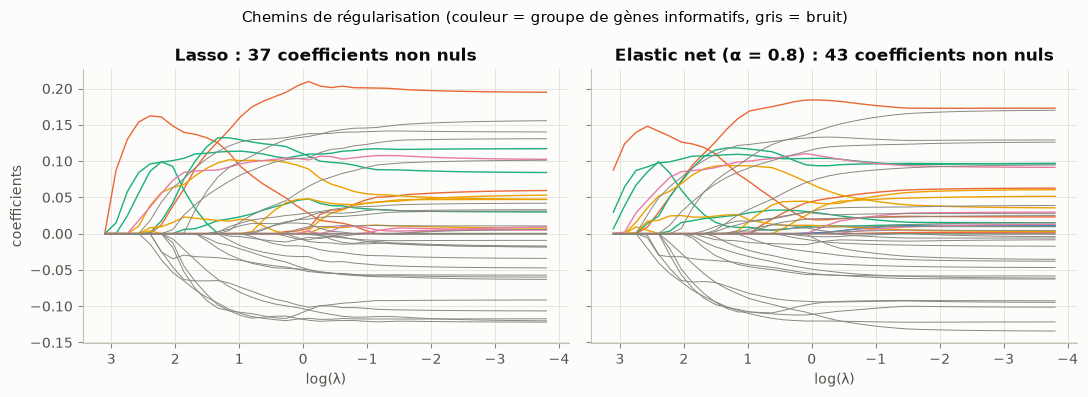

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
informative = np.arange(50)
for ax, P, title in [(axes[0], path_lasso, "Lasso"), (axes[1], path_enet, "Elastic net (α = 0.8)")]:
    for j in range(p):
        if np.any(P[:, j] != 0):
            c = COLORS[j // 10] if j < 50 else GRAY
            ax.plot(np.log(lams), P[:, j], color=c, lw=1 if j < 50 else 0.7)
    ax.set_xlabel("log(λ)")
    ax.set_title(f"{title} : {np.count_nonzero(P[-1])} coefficients non nuls")
    ax.invert_xaxis()
axes[0].set_ylabel("coefficients")
fig.suptitle("Chemins de régularisation (couleur = groupe de gènes informatifs, gris = bruit)",
             fontsize=11)
plt.tight_layout()
plt.show()

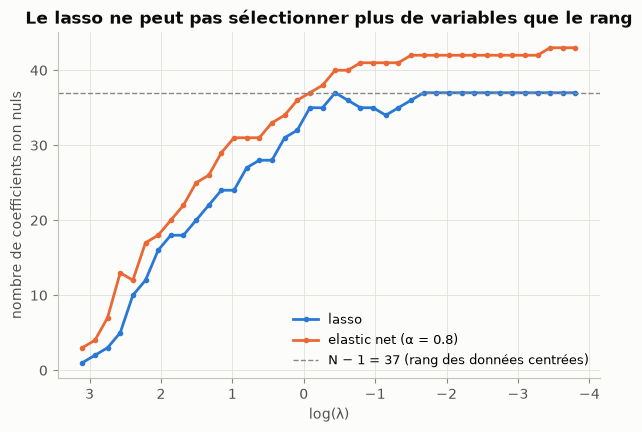

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(np.log(lams), (path_lasso != 0).sum(1), "o-", ms=3, color=BLUE, label="lasso")
ax.plot(np.log(lams), (path_enet != 0).sum(1), "o-", ms=3, color=ORANGE, label="elastic net (α = 0.8)")
ax.axhline(N - 1, color=GRAY, ls="--", lw=1, label="N − 1 = 37 (rang des données centrées)")
ax.invert_xaxis()
ax.set_xlabel("log(λ)")
ax.set_ylabel("nombre de coefficients non nuls")
ax.set_title("Le lasso ne peut pas sélectionner plus de variables que le rang")
ax.legend()
plt.show()

**Lecture.** Le nombre de variables du lasso plafonne au rang des données
($N - 1 = 37$ après centrage) ; l'elastic net le dépasse. Les premiers gènes à entrer
(grands $\lambda$) sont bien des gènes informatifs (en couleur) ; quand $\lambda$
diminue, les deux méthodes finissent par sélectionner aussi beaucoup de gènes de
bruit (en gris), signe de sur-ajustement : avec 38 observations et 500 gènes, on peut
toujours trouver des gènes de bruit corrélés par hasard à la réponse. L'elastic net
retient davantage de gènes, avec des coefficients un peu plus petits.

### Le *fused lasso* pour des données fonctionnelles (section 18.4.2)

Quand les variables ont un **ordre naturel** (positions sur le génome, longueurs
d'onde, temps…), on peut pénaliser aussi les **différences** entre coefficients
voisins (éq. (18.22)) :
$$\min_\beta\ \sum_{i=1}^N\Big(y_i - \beta_0 - \sum_j x_{ij}\beta_j\Big)^2 + \lambda_1\sum_{j=1}^p|\beta_j| + \lambda_2\sum_{j=1}^{p-1}|\beta_{j+1} - \beta_j| .$$
Le premier terme L1 rend $\beta$ **parcimonieux**, le second le rend **constant par
morceaux** (beaucoup de différences exactement nulles).

**Approximateur de signal** (éq. (18.24)). Cas particulier $\mathbf X = I_N$ : on
approche une suite $y_1,\dots,y_N$ par une suite $\beta$ parcimonieuse et constante par
morceaux. Application typique : données de **CGH** (hybridation génomique
comparative), où $y_i$ est le log-rapport du nombre de copies du gène $i$ dans une
tumeur par rapport à un tissu sain. Des régions entières du génome sont amplifiées
($y > 0$) ou délétées ($y < 0$).

**Calcul.** Pour $\lambda_1 = 0$, le problème est le débruitage par **variation
totale** ; nous le résolvons par une méthode de gradient projeté sur le problème dual
(fonction `tv_denoise`). Un résultat de Friedman et al. (2007) montre que la solution
pour $\lambda_1 > 0$ s'obtient ensuite en appliquant simplement le seuillage doux de
niveau $\lambda_1$ à la solution obtenue pour $\lambda_1 = 0$.

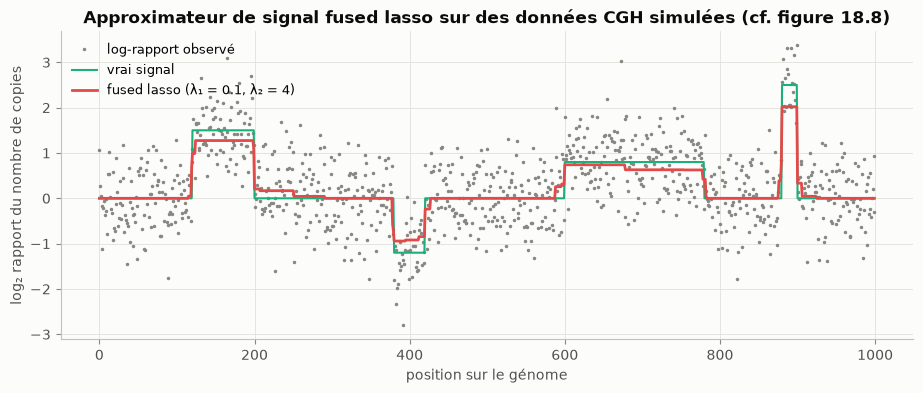

In [11]:
rng = np.random.RandomState(3)
n = 1000
truth = np.zeros(n)
for a, b, h in [(120, 200, 1.5), (380, 420, -1.2), (600, 780, 0.8), (880, 900, 2.5)]:
    truth[a:b] = h
y_cgh = truth + 0.6 * rng.randn(n)
beta_fl = g.fused_lasso_signal(y_cgh, lam1=0.1, lam2=4.0)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(y_cgh, ".", ms=3, color=GRAY, label="log-rapport observé")
ax.plot(truth, color=COLORS[2], lw=1.5, label="vrai signal")
ax.plot(beta_fl, color=COLORS[7], lw=2, label="fused lasso (λ₁ = 0.1, λ₂ = 4)")
ax.set_xlabel("position sur le génome")
ax.set_ylabel("log₂ rapport du nombre de copies")
ax.set_title("Approximateur de signal fused lasso sur des données CGH simulées (cf. figure 18.8)")
ax.legend(loc="upper left")
plt.show()

L'estimation est constante par morceaux et nulle hors des régions altérées : on
**détecte** directement les gains et les pertes. La région courte (positions
880–900) est retrouvée mais sous-estimée en hauteur : c'est le biais habituel des
pénalités L1.

Effet de $\lambda_2$ : nombre de morceaux constants de l'estimation (on compte les
sauts de taille $> 10^{-4}$).

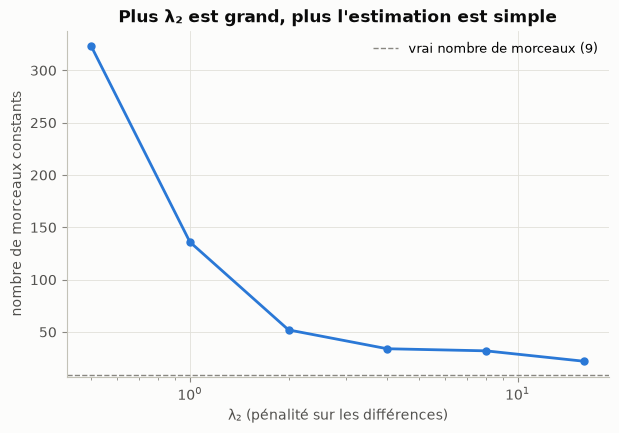

In [12]:
lam2_grid = [0.5, 1, 2, 4, 8, 16]
fig, ax = plt.subplots(figsize=(7, 4.5))
nb_pieces = []
for lam2 in lam2_grid:
    b = g.fused_lasso_signal(y_cgh, 0.1, lam2)
    nb_pieces.append(1 + np.sum(np.abs(np.diff(b)) > 1e-4))
ax.semilogx(lam2_grid, nb_pieces, "o-", color=BLUE)
ax.axhline(9, color=GRAY, ls="--", lw=1, label="vrai nombre de morceaux (9)")
ax.set_xlabel("λ₂ (pénalité sur les différences)")
ax.set_ylabel("nombre de morceaux constants")
ax.set_title("Plus λ₂ est grand, plus l'estimation est simple")
ax.legend()
plt.show()

## 4. Classification quand les variables ne sont pas disponibles (section 18.5)

Pour certains objets (protéines, textes, graphes…), il n'est pas naturel de définir
un vecteur de variables, mais on sait calculer une **similarité** entre deux objets.
Si cette similarité est un **produit scalaire** $\langle\Phi(x),\Phi(x')\rangle$ pour
une certaine représentation $\Phi$ (éventuellement de très grande dimension), on peut
utiliser beaucoup de nos classifieurs sans jamais calculer $\Phi$.

### 4.1 Noyau de chaînes (*string kernel*)

Une protéine est une chaîne de lettres parmi 20 acides aminés. Pour une longueur $m$,
on note $\phi_a(x)$ le nombre d'occurrences de la sous-chaîne $a$ (de longueur $m$)
dans $x$, et $\Phi_m(x) = (\phi_a(x))_{a\in\mathcal A^m}$ (éq. (18.25)), vecteur de
dimension $20^m$ ($160\,000$ pour $m = 4$). Le **noyau de spectre** est (éq. (18.26))
$$K_m(x_1,x_2) = \langle\Phi_m(x_1),\Phi_m(x_2)\rangle = \sum_{a\in\mathcal A^m}\phi_a(x_1)\phi_a(x_2).$$
Il se calcule sans former $\Phi_m$ : il suffit de compter les sous-chaînes présentes.

**Données simulées.** Les données de Leslie et al. du livre ne sont pas disponibles ;
nous simulons 500 « protéines » aléatoires de longueur 75 à 160, dont 50 positives.
Les positives contiennent en moyenne 2 copies de « motifs » de 4 lettres (choisis
parmi 6), les négatives 0.3 en moyenne : le signal est faible et noyé dans la
séquence. Comme les longueurs varient, on utilise le noyau **normalisé**
$K(x,x')/\sqrt{K(x,x)K(x',x')}$ (produit scalaire des vecteurs $\Phi$ normalisés).

In [13]:
AA = np.array(list("ACDEFGHIKLMNPQRSTVWY"))
motifs = ["LQEL", "KKWG", "HRTV", "PDYS", "MNQA", "WWCF"]
rng = np.random.RandomState(0)


def make_protein(positive):
    L = rng.randint(75, 161)
    s = "".join(rng.choice(AA, L))
    for _ in range(rng.poisson(2.0 if positive else 0.3)):
        m = motifs[rng.randint(len(motifs))]
        i = rng.randint(0, L - 4)
        s = s[:i] + m + s[i + 4:]
    return s


y_prot = np.r_[np.ones(50, bool), np.zeros(450, bool)]
proteins = [make_protein(v) for v in y_prot]
print(proteins[0][:60], "...")

SAEEILYWFHPCHIRVGQKLYTYGSSAWEVYYYRIACLAMENWDAAFGHKVSFLMCCILE ...


In [14]:
def spectrum(s, m=4):
    """Comptages des sous-chaînes de longueur m (seulement celles présentes)."""
    return Counter(s[i:i + m] for i in range(len(s) - m + 1))


specs = [spectrum(s) for s in proteins]
vocab = {a: i for i, a in enumerate(sorted(set().union(*specs)))}
Phi = np.zeros((len(proteins), len(vocab)))
for i, sp in enumerate(specs):
    for a, c in sp.items():
        Phi[i, vocab[a]] = c
K_raw = Phi @ Phi.T
dg = np.sqrt(np.diag(K_raw))
K_prot = K_raw / np.outer(dg, dg)
print(f"{len(vocab)} sous-chaînes distinctes observées sur 20^4 = {20 ** 4} possibles")
print("exemple : K_4(x1, x2) brut =", K_raw[0, 1])

48046 sous-chaînes distinctes observées sur 20^4 = 160000 possibles
exemple : K_4(x1, x2) brut = 1.0


> **Remarque.** Nous formons ici la matrice creuse des comptages pour aller vite ;
> on pourrait remplir chaque $K(x,x')$ directement en comparant les deux dictionnaires
> de sous-chaînes, sans jamais énumérer les $20^4$ coordonnées.

### 4.2 Classifieurs fondés uniquement sur les produits scalaires

- **Distances** (éq. (18.27)) :
  $\|x_i - x_{i'}\|^2 = \langle x_i,x_i\rangle + \langle x_{i'},x_{i'}\rangle - 2\langle x_i,x_{i'}\rangle$.
- **Distance au centroïde** de la classe $k$ (éq. (18.28)) : en développant
  $\|x_0 - \bar x_k\|^2$ avec $\bar x_k = \frac1{N_k}\sum_{g_i = k}x_i$ et la bilinéarité
  du produit scalaire,
  $$\|x_0-\bar x_k\|^2 = \langle x_0,x_0\rangle - \frac2{N_k}\sum_{g_i=k}\langle x_0,x_i\rangle + \frac1{N_k^2}\sum_{g_i=k}\sum_{g_{i'}=k}\langle x_i,x_{i'}\rangle .$$
- **1-plus-proche-voisin pondéré** : score $\log\big(d_-(x_0)/d_+(x_0)\big)$ où $d_\pm$
  est la distance au plus proche voisin de chaque classe (exercice 18.14).
- **SVM** : il ne dépend des données qu'à travers $\mathbf K$ (chapitre 12) ; nous
  utilisons `sklearn.svm.SVC(kernel="precomputed")` (SVM à marge maximale, $C$ très
  grand), déjà étudié au chapitre 12.

Vérifions d'abord (18.28) sur des données où les vecteurs sont connus.

In [15]:
rng = np.random.RandomState(1)
Xa = rng.randn(30, 8)
ya = rng.randint(0, 3, 30)
X0 = rng.randn(4, 8)
_, D2_kernel = g.kernel_centroid_distances(Xa @ Xa.T, X0 @ Xa.T, (X0 ** 2).sum(1), ya)
D2_direct = np.stack([((X0 - Xa[ya == k].mean(0)) ** 2).sum(1) for k in range(3)], axis=1)
print("écart max (18.28) vs calcul direct :", np.max(np.abs(D2_kernel - D2_direct)))

écart max (18.28) vs calcul direct : 1.7763568394002505e-15


**Courbes ROC par validation croisée** (analogue de la figure 18.9). Pour chaque
méthode on calcule, par validation croisée à 10 plis, un score réel pour chaque
protéine, puis la courbe (spécificité, sensibilité) obtenue en faisant varier le seuil.
L'**aire sous la courbe** (AUC) vaut la probabilité qu'une positive tirée au hasard
ait un score plus élevé qu'une négative tirée au hasard.

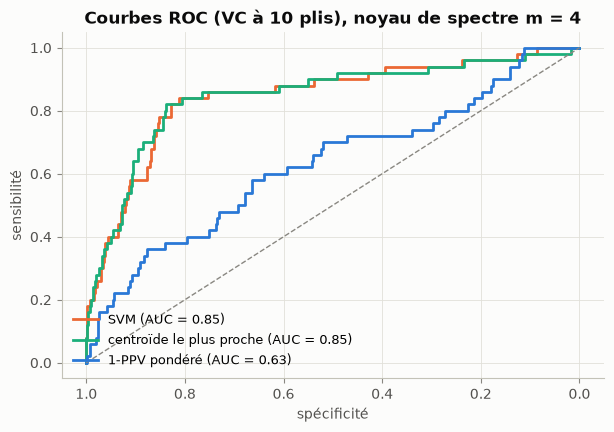

In [16]:
from sklearn.svm import SVC

folds = g.stratified_folds(y_prot, 10, np.random.RandomState(2))
n_p = len(y_prot)
sc_svm, sc_nc, sc_nn = np.zeros(n_p), np.zeros(n_p), np.zeros(n_p)
kdiag = np.diag(K_prot)
for f in range(10):
    a, b = folds != f, folds == f
    Kaa, Kba = K_prot[np.ix_(a, a)], K_prot[np.ix_(b, a)]
    sc_svm[b] = SVC(kernel="precomputed", C=1e6).fit(Kaa, y_prot[a]).decision_function(Kba)
    cls, D2 = g.kernel_centroid_distances(Kaa, Kba, kdiag[b], y_prot[a])  # classes [False, True]
    sc_nc[b] = D2[:, 0] - D2[:, 1]
    Dd = np.maximum(g.kernel_distances(Kaa, Kba, kdiag[b]), 1e-12)
    pos = y_prot[a]
    sc_nn[b] = 0.5 * (np.log(Dd[:, ~pos].min(1)) - np.log(Dd[:, pos].min(1)))

fig, ax = plt.subplots(figsize=(7, 4.5))
for sc, name, c in [(sc_svm, "SVM", ORANGE), (sc_nc, "centroïde le plus proche", COLORS[2]),
                    (sc_nn, "1-PPV pondéré", BLUE)]:
    fpr, tpr, auc = g.roc_curve(sc, y_prot)
    ax.plot(1 - fpr, tpr, color=c, label=f"{name} (AUC = {auc:.2f})")
ax.plot([1, 0], [0, 1], color=GRAY, lw=1, ls="--")
ax.invert_xaxis()
ax.set_xlabel("spécificité")
ax.set_ylabel("sensibilité")
ax.set_title("Courbes ROC (VC à 10 plis), noyau de spectre m = 4")
ax.legend(loc="lower left")
plt.show()

Le SVM et le centroïde le plus proche, qui n'utilisent que $\mathbf K$, détectent
assez bien les protéines porteuses de motifs. Le 1-plus-proche-voisin est plus faible
ici : avec un signal ténu et beaucoup de « bruit » dans la séquence, le voisin le plus
proche est souvent dû au hasard (dans l'exemple réel du livre, les trois méthodes font
jeu égal).

### 4.3 ACP et distances à partir des produits scalaires

Si $\mathbf X$ est centrée, $\mathbf X = \mathbf U\mathbf D\mathbf V^T$ et
$\mathbf K = \mathbf X\mathbf X^T = \mathbf U\mathbf D^2\mathbf U^T$ : les composantes
principales $\mathbf Z = \mathbf U\mathbf D$ se lisent sur la décomposition spectrale
de $\mathbf K$. Si $\mathbf X$ n'est pas centrée, on la centre par
$\tilde{\mathbf X} = (I - \mathbf M)\mathbf X$ avec $\mathbf M = \frac1N\mathbf 1\mathbf 1^T$,
d'où le **double centrage** $(I-\mathbf M)\mathbf K(I-\mathbf M)$.

Si l'on ne dispose que des **distances** $\Delta_{ii'}^2 = \|x_i - x_{i'}\|^2$
(éq. (18.29)), on écrit (éq. (18.30))
$\Delta^2_{ii'} = \|x_i-\bar x\|^2 + \|x_{i'}-\bar x\|^2 - 2\langle x_i - \bar x, x_{i'}-\bar x\rangle$
et l'on double-centre $\mathbf B = (-\Delta^2_{ii'}/2)$ (éq. (18.31)) :
$\tilde{\mathbf K} = (I-\mathbf M)\mathbf B(I-\mathbf M)$ est la matrice des produits
scalaires **centrés**. En effet, le double centrage annule les termes qui ne dépendent
que de $i$ ou que de $i'$, ainsi que les constantes.

In [17]:
rng = np.random.RandomState(4)
Xd = rng.randn(25, 6) + 3.0
Dist2 = ((Xd[:, None, :] - Xd[None]) ** 2).sum(2)
K_tilde = g.double_center(-Dist2 / 2)
Xd_c = Xd - Xd.mean(0)
print("écart max entre (I-M)B(I-M) et les produits scalaires centrés :",
      np.max(np.abs(K_tilde - Xd_c @ Xd_c.T)))

écart max entre (I-M)B(I-M) et les produits scalaires centrés : 5.329070518200751e-15


Appliquons l'ACP à noyau aux protéines : la première composante, calculée **sans
jamais voir la classe**, sépare-t-elle les positives ?

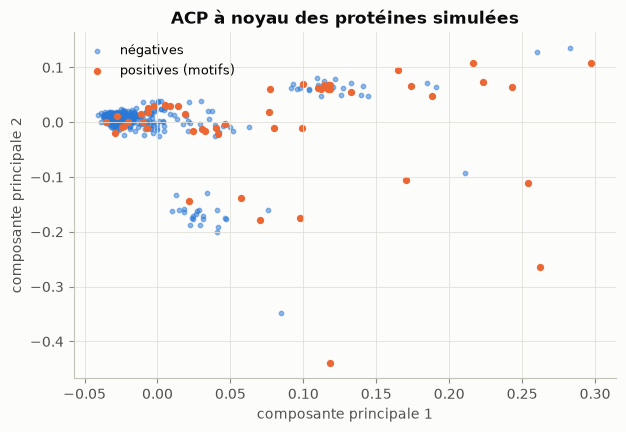

In [18]:
Zp, Up, dp = g.kernel_pca(K_prot, 2)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(Zp[~y_prot, 0], Zp[~y_prot, 1], s=10, color=BLUE, alpha=0.5, label="négatives")
ax.scatter(Zp[y_prot, 0], Zp[y_prot, 1], s=18, color=ORANGE, label="positives (motifs)")
ax.set_xlabel("composante principale 1")
ax.set_ylabel("composante principale 2")
ax.set_title("ACP à noyau des protéines simulées")
ax.legend()
plt.show()

Les protéines qui partagent un même motif forment de petits amas écartés du nuage
central (le noyau normalisé y est grand), et les positives y sont sur-représentées :
l'ACP à noyau capte en partie la structure des motifs **sans connaître la classe**.
Mais beaucoup de positives restent mêlées au nuage central et des négatives porteuses
de motifs se retrouvent dans les amas : la séparation reste imparfaite.

### 4.4 Ce que l'on ne peut **pas** faire avec seulement des noyaux

- **standardiser** les variables (il faudrait la variance de chaque variable) ;
- évaluer la contribution de **chaque variable** (tests $t$, centroïdes réduits, lasso…) ;
- **séparer** les variables utiles du bruit : toutes les variables ont le même poids.

Le livre l'illustre sur des résumés d'articles (tableau 18.3) : les centroïdes réduits,
qui standardisent chaque mot, battent les méthodes à noyau. Simulons ce phénomène :
50 variables informatives de **petite** variance, 950 variables de bruit de **grande**
variance.

In [19]:
rng = np.random.RandomState(5)
n_tr, n_te, p = 60, 600, 1000
scales = np.r_[0.3 * np.ones(50), 3.0 * np.ones(950)]
class_means = 0.25 * rng.randn(3, 50)      # centroïdes des 3 classes sur les 50 variables utiles


def make_abstracts(n):
    yv = rng.randint(0, 3, n)
    Xv = rng.randn(n, p) * scales
    Xv[:, :50] += class_means[yv]
    return Xv, yv


Xa_tr, ya_tr = make_abstracts(n_tr)
Xa_te, ya_te = make_abstracts(n_te)
err_nc = np.mean(nearest_centroid(Xa_tr, ya_tr, Xa_te) != ya_te)
err_nsc0 = np.mean(g.NearestShrunkenCentroids(0.0, s0=0.0).fit(Xa_tr, ya_tr).predict(Xa_te) != ya_te)
err_1nn = np.mean(one_nn(Xa_tr, ya_tr, Xa_te) != ya_te)
print(f"centroïde le plus proche (métrique sphérique, faisable par noyau) : {err_nc:.2f}")
print(f"1 plus proche voisin (faisable par noyau)                          : {err_1nn:.2f}")
print(f"LDA diagonale (standardisation de chaque variable par s_j)         : {err_nsc0:.2f}")

centroïde le plus proche (métrique sphérique, faisable par noyau) : 0.67
1 plus proche voisin (faisable par noyau)                          : 0.69
LDA diagonale (standardisation de chaque variable par s_j)         : 0.03


Sans standardisation, les 950 variables bruitées de grande variance dominent les
distances et l'on est proche du hasard ($2/3$ d'erreur) ; en divisant chaque variable
par son écart-type intra-classe $s_j$ (LDA diagonale, ici avec $s_0 = 0$), on retrouve
le signal. Ce calcul exige l'accès à **chaque variable** : il est impossible avec la
seule matrice $\mathbf K$.

## Bilan

> **À retenir.**
> - Pour tout modèle linéaire à **pénalité quadratique**, on peut remplacer les
>   $x_i\in\mathbb R^p$ par leurs coordonnées $r_i\in\mathbb R^N$ (SVD) puis revenir à
>   $\hat\beta = \mathbf V\hat\theta$ : coût $O(N^2p)$ au lieu de $O(p^3)$. C'est la
>   même idée que l'astuce du noyau.
> - Les pénalités **L1** sélectionnent des variables ; le lasso en garde au plus $N$,
>   l'elastic net peut en garder plus et traite mieux les groupes corrélés ; le
>   *fused lasso* exploite un ordre entre variables.
> - Avec seulement des **produits scalaires** ou des **distances**, on peut encore
>   faire du plus proche voisin, des centroïdes, des SVM, de l'ACP… mais pas de
>   standardisation ni de sélection de variables.